# Propagating protons: continuous cooling versus discrete pp collisions

Compare **final proton spectra, mean kinetic energy, and the uncollided fraction**, using identical initial particles, hydrogen density and propagation duration. The historical filenames `pion_decay_mc.cpp` and `pion_decay_comparison.ipynb` are retained; this benchmark no longer generates gamma rays.

Run `make pion_decay_mc` and `./pion_decay_mc` in the project directory, then execute this notebook from there or `output/`. The generator overwrites `output/pp_loss_comparison_4cases_t1e9.bin`; the old photon file `pion_decay_events.bin` is not used.

We use constant $n_H=1$ cm$^{-3}$, $t=10^9$ yr, $\kappa=0.5$, and the same $v=c$ convention as `transport_loss_stochastic.cpp`. No wind, adiabatic cooling, escape, or other reactions are included. In homogeneous gas with a common residence time, diffusion changes positions but cannot change collision exposure, so spatial random walks can be omitted exactly for this comparison.

Four equal-weight ensembles, each of 100,000 protons: (0) $dN/dT_0\propto T_0^{-1}$ from 10 to $10^6$ GeV; (1) monoenergetic $T_0=1000$ GeV, energy-dependent cross section; (2) the same monoenergetic population with cross section frozen at its initial value, as an analytic control; (3) $dN/dE_0\propto E_0^{-1}$ in total energy, with the same fixed cross section as case 2. Case 3 spans $E_0=T_{\min}+m_pc^2$ to $T_{\max}+m_pc^2$, so all broad injections have the same kinetic-energy bounds. The fixed cross section is $\sigma_{pp}(T_{\rm mono})$ and remains fixed even below threshold, making cases 2 and 3 mathematical controls. Binary energy columns are kinetic energies; the total-energy plot uses $E=T+m_pc^2$.

The pp cross section follows [Kafexhiu et al. (2014), Eq. (1)](https://arxiv.org/abs/1406.7369). The fixed per-collision inelasticity is an approximate leading-proton energy-loss model, not a complete hadronic final state.

In [39]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import gammaln

N_particles = 100000         # per case, matching pion_decay_mc.cpp
T_min = 10.0                 # kinetic energy, GeV
T_max = 1e6
T_mono = 1000.0
nH = 1.0                    # cm^-3
T_end = 1e8                 # yr
kappa = 0.5
c_cm_s = 2.99792458e10
yr2s = 31557600.0
T_threshold = 0.2797         # GeV
file = Path('pp_loss_comparison_4cases_t1e8.bin')
if not file.exists():
    file = Path('output') / file
# Four native-endian float64 values per record (32 bytes).
data = np.fromfile(file, dtype='=f8').reshape(-1, 4)
case_id = data[:, 0].astype(int)
T_initial = data[:, 1]
T_final = data[:, 2]
N_collisions = data[:, 3].astype(int)
assert data.shape == (4 * N_particles, 4)
assert np.all(T_final > 0)
assert np.allclose(T_final, T_initial * (1 - kappa)**N_collisions)
print('Loaded proton records:', len(data))

Loaded proton records: 400000


## Two evolution models

Define $\Gamma(T)=n_Hc\sigma_{pp}(T)$, with consistent conversion to yr$^{-1}$. Continuous cooling solves
$$\frac{dT}{dt}=-\kappa\Gamma(T)T.$$
The reference below integrates $\ln T$ with an adaptive ODE solver; it is a numerical solution of the continuous equation, not a closed-form solution when $\sigma$ depends on energy. A log-energy grid and linear interpolation supply the cooled energies for the **same** recorded initial particles. A finer grid and tighter tolerance check this approximation.

The event MC instead samples $\Delta t=-\ln(1-u)/\Gamma(T)$, and applies $T\to(1-\kappa)T$ at every collision. The rate is recomputed after each jump. There is no propagation timestep or continuous pp loss in the MC.

For either cross section, an initially uncollided proton retains $T_0$, so its survival probability is exactly $P_0(T_0)=\exp[-\Gamma(T_0)t]$. Continuous cooling has no collision-count variable: its particles cool smoothly, and an “uncollided fraction” is not defined for that model.

In [40]:
def sigma_pp(T):
    T = np.asarray(T, dtype=float)
    safe_T = np.maximum(T, T_threshold)
    L = np.log(safe_T / T_threshold)
    sigma = (30.7 - 0.96 * L + 0.18 * L**2) * (1 - (T_threshold / safe_T)**1.9)**3 * 1e-27
    return np.where(T > T_threshold, sigma, 0.0)


def collision_rate(T):
    return nH * c_cm_s * sigma_pp(T) * yr2s


def continuous_solution(N_grid, rtol):
    T0 = np.logspace(np.log10(T_min), np.log10(T_max), N_grid)
    # Integrating ln(T) maintains positive energy. q=t/T_end is dimensionless;
    # solve_ivp integrates all initial energies as separate, uncoupled ODEs.
    def rhs(q, logT):
        return -T_end * kappa * collision_rate(np.exp(logT))
    sol = solve_ivp(rhs, (0, 1), np.log(T0), rtol=rtol, atol=rtol * 0.01)
    assert sol.success, sol.message
    return T0, np.exp(sol.y[:, -1])


T0_grid, Tf_grid = continuous_solution(4097, 1e-10)
T0_fine, Tf_fine = continuous_solution(8193, 1e-12)
# np.interp linearly interpolates ln(T_final) as a function of ln(T_initial).
T_continuous = np.exp(np.interp(np.log(T_initial), np.log(T0_grid), np.log(Tf_grid)))
T_check = np.exp(np.interp(np.log(T_initial), np.log(T0_fine), np.log(Tf_fine)))
fixed_rate = collision_rate(T_mono)
fixed = (case_id == 2) | (case_id == 3)
T_continuous[fixed] = T_initial[fixed] * np.exp(-kappa * fixed_rate * T_end)
T_check[fixed] = T_continuous[fixed]
print('Maximum continuous-reference refinement change:', np.max(np.abs(T_continuous / T_check - 1)))

P0 = np.exp(-collision_rate(T_initial) * T_end)
P0[fixed] = np.exp(-fixed_rate * T_end)
labels = ['Log-uniform, energy-dependent sigma', 'Mono, energy-dependent sigma', 'Mono, fixed sigma', 'Log-uniform total E, fixed sigma']
print('Case | mean T_MC | mean T_cont [GeV] | paired difference +/- SE | uncollided MC | exact P0 +/- SE')
for j in range(4):
    selected = case_id == j
    difference = T_final[selected] - T_continuous[selected]
    difference_error = difference.std(ddof=1) / np.sqrt(N_particles)
    p = P0[selected]
    survival_error = np.sqrt(np.sum(p * (1 - p))) / N_particles
    observed_P0 = np.mean(N_collisions[selected] == 0)
    print(f'{j}: {T_final[selected].mean():.3f} | {T_continuous[selected].mean():.3f} | '
          f'{difference.mean():.3f} +/- {difference_error:.3f} | '
          f'{observed_P0:.5f} | {p.mean():.5f} +/- {survival_error:.5f}')
# Paired SE describes variation across independent initial-particle/collision
# draws. It measures the mean model difference, not ODE integration uncertainty.

Maximum continuous-reference refinement change: 5.610053377402835e-08
Case | mean T_MC | mean T_cont [GeV] | paired difference +/- SE | uncollided MC | exact P0 +/- SE
0: 8154.609 | 8780.056 | -625.447 +/- 80.259 | 0.03000 | 0.03087 +/- 0.00054
1: 201.883 | 205.442 | -3.559 +/- 0.686 | 0.03704 | 0.03683 +/- 0.00060
2: 192.625 | 191.923 | 0.702 +/- 0.690 | 0.03728 | 0.03683 +/- 0.00060
3: 17047.055 | 16953.012 | 94.043 +/- 143.337 | 0.03848 | 0.03683 +/- 0.00060


In [46]:
np.exp(-0.5 * sigma_pp(1000) *c_cm_s*1e8*yr2s)

np.float64(0.1919232633530157)

## Final kinetic-energy spectra

The initial population, final MC population and continuously cooled population use the same kinetic-energy bins and absolute particle-count normalization. Counts/$\Delta\ln T$ are the bin-average $dN/d\ln T$. The monoenergetic continuous prediction is a delta function, shown as a line at its cooled energy rather than an artificial broad histogram. The MC peaks correspond to integer collision counts. The fixed-cross-section control demonstrates that equal mean energies do not imply equal spectra.

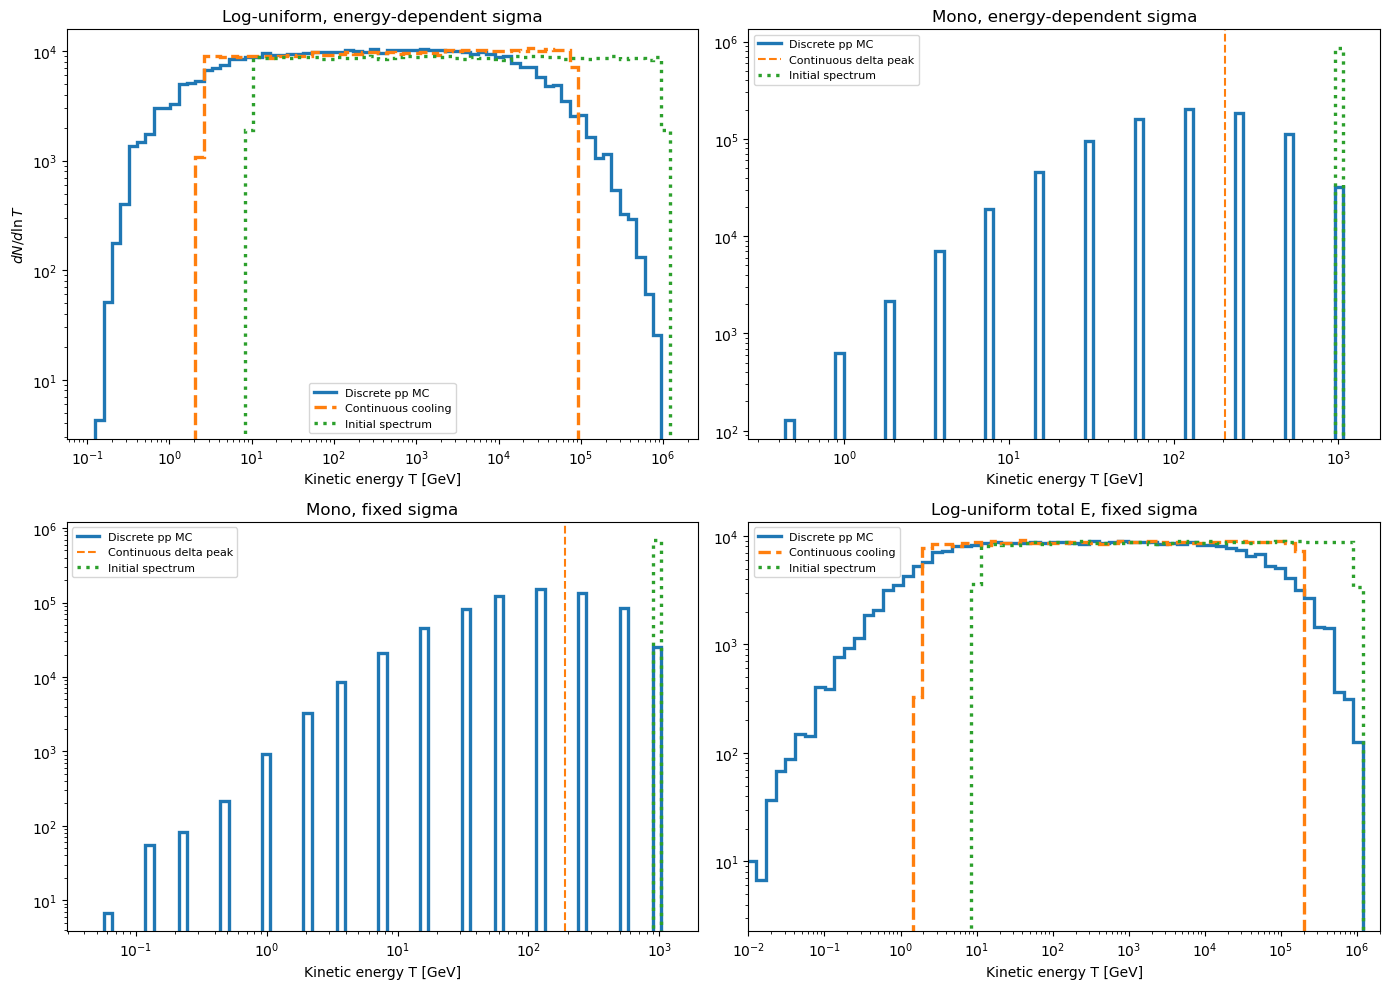

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for j in range(4):
    selected = case_id == j
    low = min(T_final[selected].min(), T_continuous[selected].min()) * 0.8
    high = T_initial[selected].max() * 1.2
    bins = np.logspace(np.log10(low), np.log10(high), 70)
    dlnt = np.diff(np.log(bins))
    counts = np.histogram(T_final[selected], bins=bins)[0]
    axes[j].stairs(counts / dlnt, bins, linewidth=2.4, label='Discrete pp MC')
    if j == 0 or j == 3:
        cooled_counts = np.histogram(T_continuous[selected], bins=bins)[0]
        axes[j].stairs(cooled_counts / dlnt, bins, linestyle='--', linewidth=2.4, label='Continuous cooling')
    else:
        axes[j].axvline(T_continuous[selected].mean(), color='C1', linestyle='--', label='Continuous delta peak')
    initial_counts = np.histogram(T_initial[selected], bins=bins)[0]
    assert initial_counts.sum() == N_particles
    axes[j].stairs(initial_counts / dlnt, bins, color='C2', linestyle=':',
                   linewidth=2.4, label='Initial spectrum')
    axes[j].set_xscale('log')
    axes[j].set_yscale('log')
    axes[j].set_xlabel('Kinetic energy T [GeV]')
    axes[j].set_title(labels[j])
    axes[j].legend(fontsize=8)
axes[0].set_ylabel(r'$dN/d\ln T$')
axes[3].set_xlim(1e-2, 2e6)
fig.tight_layout()
plt.show()

## Final spectra $dN/d\ln E$

Here $E=T+m_pc^2$ is the total proton energy in GeV, with $m_pc^2=0.9382720813$ GeV. The preceding figure uses kinetic energy $T$. For each bin,
$$\left(\frac{dN}{d\ln E}\right)_i=\frac{N_i}{\ln(E_{i+1}/E_i)}.$$
The initial population and both final populations use the same total-energy bins and retain their absolute particle counts. The initial spectrum is calculated from the recorded initial energies, including the conversion $E_0=T_0+m_pc^2$. The continuous monoenergetic delta peak is represented by its bin-average height here; that height depends on the bin width, while its integrated particle count is unchanged.


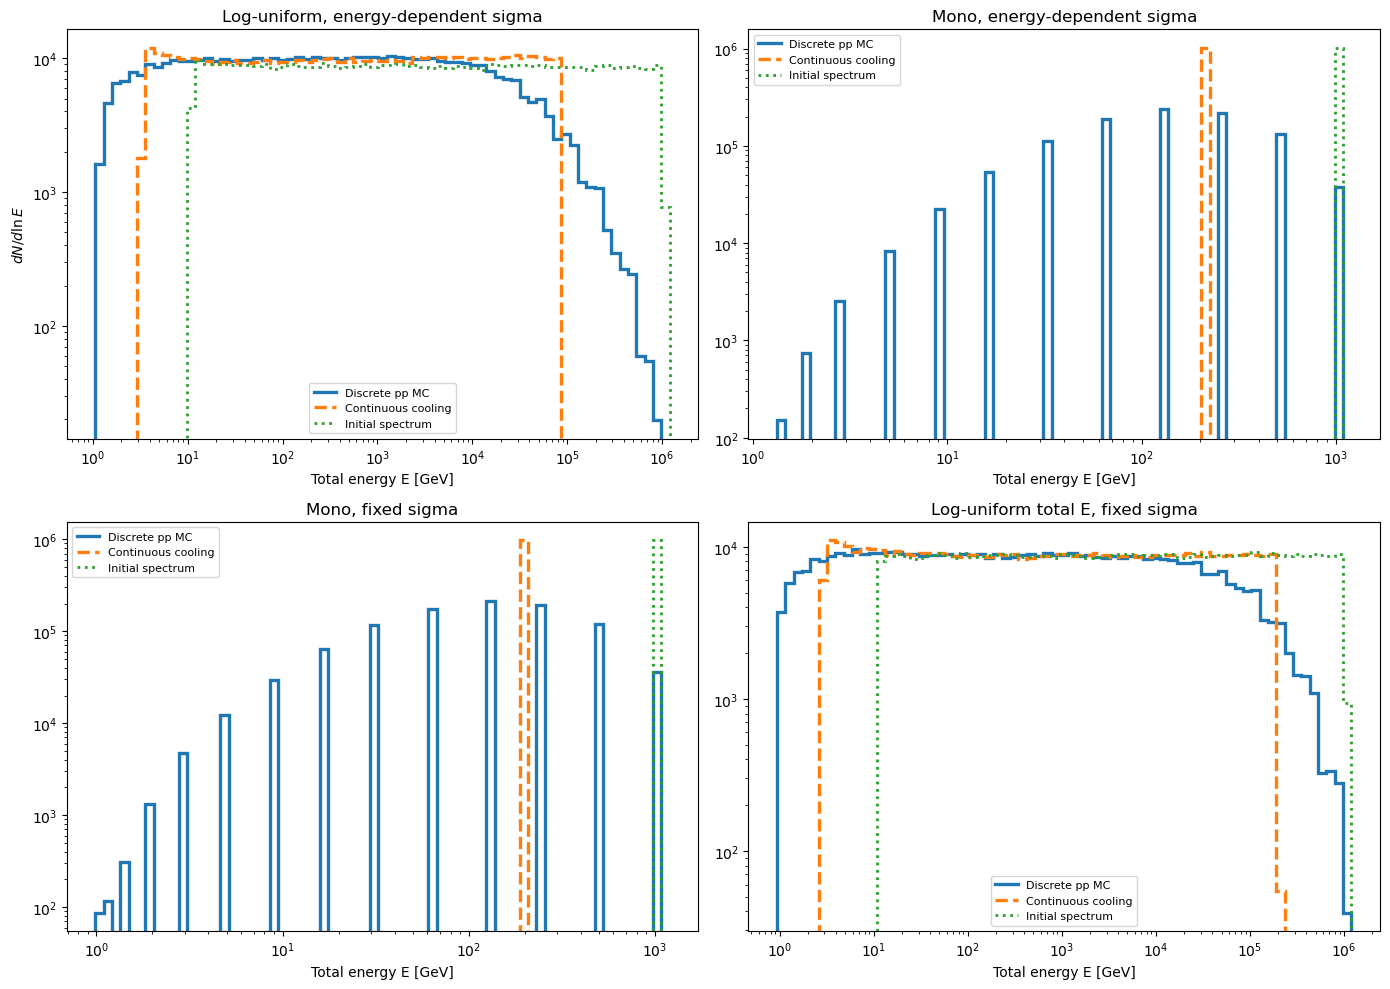

In [43]:
m_p_GeV = 0.9382720813  # proton rest energy m_p c^2, GeV
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for j in range(4):
    selected = case_id == j
    E_initial = T_initial[selected] + m_p_GeV
    E_final = T_final[selected] + m_p_GeV  # total energy, GeV
    E_continuous = T_continuous[selected] + m_p_GeV
    E_low = m_p_GeV + min(T_final[selected].min(), T_continuous[selected].min()) * 0.8
    E_high = m_p_GeV + T_initial[selected].max() * 1.2
    E_bins = np.logspace(np.log10(E_low), np.log10(E_high), 70)
    delta_lnE = np.log(E_bins[1:] / E_bins[:-1])
    initial_counts = np.histogram(E_initial, bins=E_bins)[0]
    final_counts = np.histogram(E_final, bins=E_bins)[0]
    continuous_counts = np.histogram(E_continuous, bins=E_bins)[0]
    dN_dlnE_initial = initial_counts / delta_lnE
    dN_dlnE_final = final_counts / delta_lnE
    dN_dlnE_continuous = continuous_counts / delta_lnE

    axes[j].stairs(dN_dlnE_final, E_bins, linewidth=2.4, label='Discrete pp MC')
    axes[j].stairs(dN_dlnE_continuous, E_bins, linestyle='--', linewidth=2.4, label='Continuous cooling')
    axes[j].stairs(dN_dlnE_initial, E_bins, color='C2', linestyle=':',
                   linewidth=2, label='Initial spectrum')
    axes[j].set_xscale('log')
    axes[j].set_yscale('log')
    axes[j].set_xlabel('Total energy E [GeV]')
    axes[j].set_title(labels[j])
    axes[j].legend(fontsize=8)
axes[0].set_ylabel(r'$dN/d\ln E$')
fig.tight_layout()
plt.show()


## Fixed-cross-section analytic control

For $\tau=\Gamma t$, the number of collisions is Poisson distributed:
$$P_n=e^{-\tau}\frac{\tau^n}{n!},\quad T_n=T_0(1-\kappa)^n,\quad
\langle T\rangle=T_0e^{-\kappa\tau},\quad
\operatorname{Var}(T)=\langle T\rangle^2(e^{\kappa^2\tau}-1),\quad P_0=e^{-\tau}.$$
The mean equals the continuous solution exactly, while the variance is nonzero. This frozen-cross-section case is a mathematical control, not a physical threshold model.

For the energy-dependent monoenergetic case, a separate master equation predicts the probability of every collision count: $\dot P_0=-\Gamma_0P_0$, $\dot P_n=\Gamma_{n-1}P_{n-1}-\Gamma_nP_n$, with $\Gamma_n=\Gamma[T_0(1-\kappa)^n]$. Once below threshold, the final state is absorbing. This independent reference checks the event MC without replacing it by continuous cooling.

Fixed-sigma optical depth: 3.301319313760176
Mean: MC / analytic / continuous: 192.62485412597655 191.9232633530157 191.9232633530157
Mean residual [SE]: 1.0207160803877395
Variance: MC / analytic: 47591.257928004736 47245.214385496045
Energy-dependent MC / master mean [GeV]: 201.8826318359375 201.1009717961098
MC-master mean residual [SE]: 1.1424281308679476


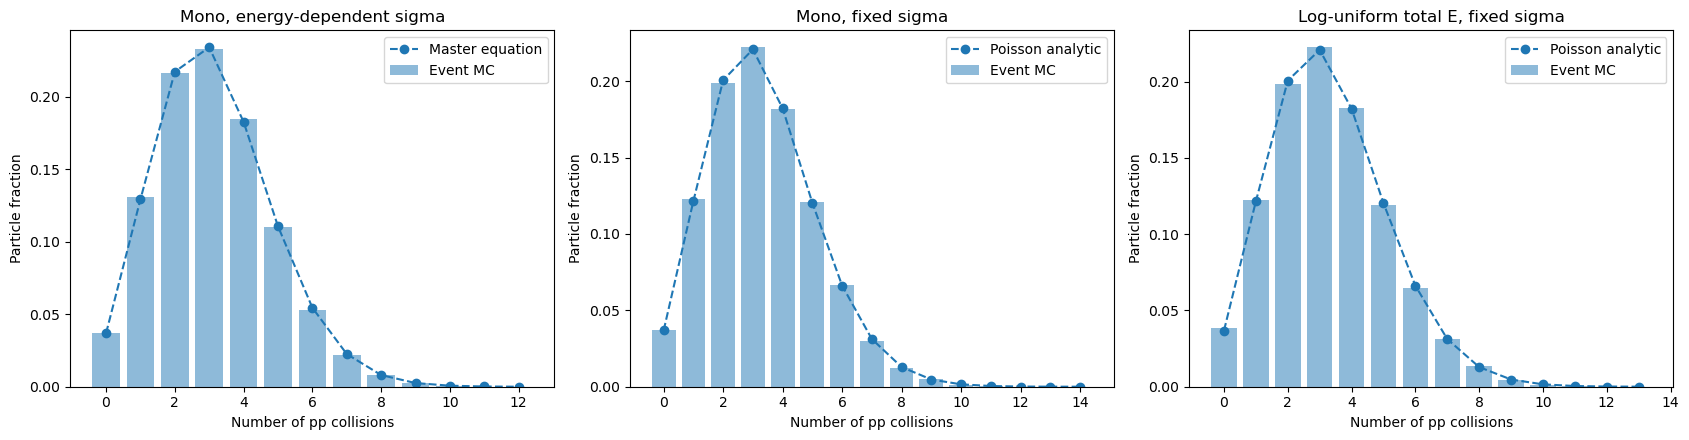

In [44]:
tau = fixed_rate * T_end
exact_mean = T_mono * np.exp(-kappa * tau)
exact_variance = exact_mean**2 * np.expm1(kappa**2 * tau)
fixed_energy = T_final[case_id == 2]
print('Fixed-sigma optical depth:', tau)
print('Mean: MC / analytic / continuous:', fixed_energy.mean(), exact_mean, T_continuous[case_id == 2].mean())
print('Mean residual [SE]:', (fixed_energy.mean() - exact_mean) / np.sqrt(exact_variance / N_particles))
print('Variance: MC / analytic:', fixed_energy.var(ddof=1), exact_variance)

N_terminal = int(np.ceil(np.log(T_threshold / T_mono) / np.log(1 - kappa)))
collision_counts = np.arange(N_terminal + 1)
T_states = T_mono * (1 - kappa)**collision_counts
rates = collision_rate(T_states)
initial_probability = np.zeros(len(T_states))
initial_probability[0] = 1


def master_rhs(q, probability):
    # Probability flows from n collisions to n+1 at rate Gamma_n.
    flow = T_end * rates * probability
    derivative = -flow
    derivative[1:] += flow[:-1]
    return derivative


master = solve_ivp(master_rhs, (0, 1), initial_probability, rtol=1e-11, atol=1e-13)
assert master.success, master.message
probability = master.y[:, -1]
assert np.isclose(probability.sum(), 1)
mono = case_id == 1
master_mean = np.sum(probability * T_states)
master_variance = np.sum(probability * (T_states - master_mean)**2)
print('Energy-dependent MC / master mean [GeV]:', T_final[mono].mean(), master_mean)
print('MC-master mean residual [SE]:', (T_final[mono].mean() - master_mean) / np.sqrt(master_variance / N_particles))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, j in zip(axes, [1, 2, 3]):
    selected = case_id == j
    n_max = max(N_collisions[selected].max(), N_terminal)
    ns = np.arange(n_max + 1)
    observed = np.bincount(N_collisions[selected], minlength=n_max + 1) / N_particles
    if j == 1:
        theory = np.zeros(n_max + 1)
        theory[:len(probability)] = probability
    else:
        theory = np.exp(-tau + ns * np.log(tau) - gammaln(ns + 1))
    ax.bar(ns, observed, alpha=0.5, label='Event MC')
    ax.plot(ns, theory, 'o--', label='Master equation' if j == 1 else 'Poisson analytic')
    ax.set_xlabel('Number of pp collisions')
    ax.set_ylabel('Particle fraction')
    ax.set_title(labels[j])
    ax.legend()
fig.tight_layout()
plt.show()

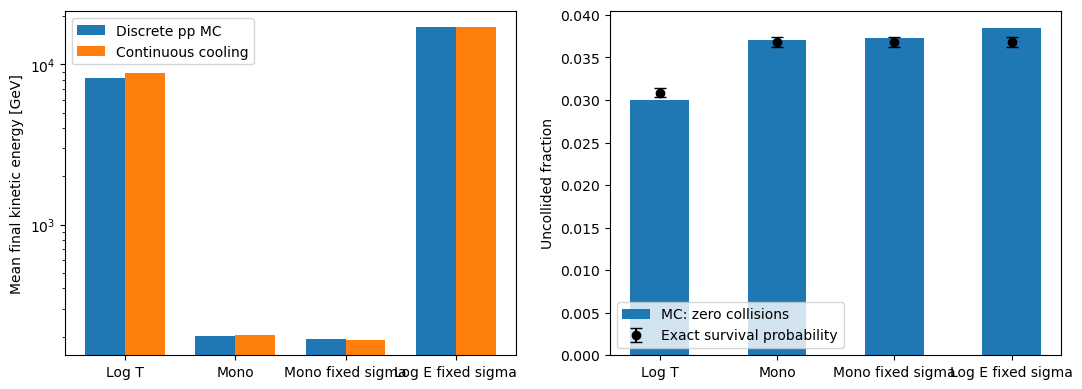

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
positions = np.arange(4)
mean_mc = np.array([T_final[case_id == j].mean() for j in range(4)])
mean_cont = np.array([T_continuous[case_id == j].mean() for j in range(4)])
axes[0].bar(positions - 0.18, mean_mc, width=0.36, linewidth=2.4, label='Discrete pp MC')
axes[0].bar(positions + 0.18, mean_cont, width=0.36, label='Continuous cooling')
axes[0].set_yscale('log')
axes[0].set_ylabel('Mean final kinetic energy [GeV]')
axes[0].legend()
observed_p0 = np.array([np.mean(N_collisions[case_id == j] == 0) for j in range(4)])
expected_p0 = np.array([P0[case_id == j].mean() for j in range(4)])
p0_error = np.array([np.sqrt(np.sum(P0[case_id == j] * (1 - P0[case_id == j]))) / N_particles for j in range(4)])
axes[1].bar(positions, observed_p0, width=0.5, label='MC: zero collisions')
axes[1].errorbar(positions, expected_p0, yerr=p0_error, fmt='ko', capsize=4, label='Exact survival probability')
axes[1].set_ylabel('Uncollided fraction')
axes[1].legend()
for ax in axes:
    ax.set_xticks(positions, ['Log T', 'Mono', 'Mono fixed sigma', 'Log E fixed sigma'])
fig.tight_layout()
plt.show()

## Reading the comparison

Continuous cooling replaces finite energy jumps by a drift. It can reproduce the first moment for constant collision rate, but cannot reproduce the uncollided peak or the spread in collision counts. With an energy-dependent rate, even the ensemble mean need not agree: the exact jump process satisfies $d\langle T\rangle/dt=-\kappa\langle\Gamma(T)T\rangle$, which is not generally the continuous equation evaluated at the mean.

A smooth spectrum can conceal these differences; monoenergetic injection exposes them directly. No independent Poisson uncertainty is assigned to the continuously cooled histogram: it uses the same initial sample as the MC. The printed paired mean differences account for this shared injection.

This benchmark isolates pp losses under identical exposure. Spatially varying gas, wind, adiabatic losses or escape would make exposure trajectory dependent and require matched spatial transport as well. It validates the fixed-inelasticity collision process, not the physical pion multiplicity or a gamma-ray spectrum.